# Late-Inspiral Waveform Modifications

In this tutorial, we see how to generate a waveform with late-inspiral amplitude and phase corrections and use it for parameter estimation using the `GWCorrect.wfu` submodule. This notebook can be downloaded [here](https://github.com/RyanSR71/GWCorrect/blob/main/docs/source/notebooks/Late-Inspiral_Corrected_Waveform_Tutorial.ipynb).

In [2]:
import os
import numpy as np
import bilby
import matplotlib.pyplot as plt
import requests
import GWCorrect.wfu as wfu

In [3]:
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'serif'

## Generating a Waveform

To generate a modified waveform, we first need to set up the conversions between the rescaled correction parameters, $\tilde\alpha_k$ and $\tilde\varphi_k$, and the true correction parameters, $\alpha_k$ and $\varphi_k$. The conversions are given by $\sigma_\mathcal{A}$ and $\sigma_\phi$, which are the standard deviations of the amplitude and phase priors. These are conveniently derived from parameterization files. We load in an example parameterization file below and generate the standard deviations as `SciPy` spline objects. See [Parameterization and Waveform Differences](https://waveformuncertainty.readthedocs.io/en/latest/notebooks/Parameterization_and_Waveform_Differences.html) for more details.

In [4]:
# downloading the file and saving to a folder
try:
    os.mkdir('tutorial_files')
except:
    pass
file = requests.get('https://github.com/RyanSR71/GWCorrect/raw/refs/heads/main/files/parameterization_example_nsamples_1000.npy', allow_redirects=True)
open("tutorial_files/BBH_parameterization_nsamples_1000.npy", 'wb').write(file.content)

# loading the file
parameterization = np.load("tutorial_files/BBH_parameterization_nsamples_1000.npy",allow_pickle=True)

sigma_A_spline, sigma_phi_spline = wfu.parameterization.sigma_splines_from_parameterization(parameterization)

Now we can create the corrected waveform generator. We simply add the splines to the waveform arguments dictionary, use `GWCorrect.wfu.waveform_generator.binary_black_hole_correction_conversion` as the parameter conversion function, and use `GWCorrect.wfu.waveform_generator.WaveformCorrectionModelBBH` as the frequency domain source model. 

In [5]:
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                          catch_waveform_errors=True, minimum_frequency = 20, maximum_frequency = 2048, 
                          # add amplitude and phase prior splines here
                          sigma_A_spline = sigma_A_spline, sigma_phi_spline = sigma_phi_spline)

corrected_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=wfu.waveform_generator.binary_black_hole_correction_conversion, #this function converts the freqency node and waveform correction parameters to lists
                                                          waveform_arguments=waveform_arguments,
                                                          frequency_domain_source_model=wfu.waveform_generator.WaveformCorrectionModelBBH, #this model adds the waveform corrections to an otherwise unmodified lal waveform
                                                          sampling_frequency=4096, 
                                                          duration=4)

20:55 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4, sampling_frequency=4096, start_time=0, frequency_domain_source_model=GWCorrect.wfu.waveform_generator.WaveformCorrectionModelBBH, time_domain_source_model=None, parameter_conversion=GWCorrect.wfu.waveform_generator.binary_black_hole_correction_conversion, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'reference_frequency': 20, 'catch_waveform_errors': True, 'minimum_frequency': 20, 'maximum_frequency': 2048, 'sigma_A_spline': <scipy.interpolate._cubic.CubicSpline object at 0x7f4bdaeb6a20>, 'sigma_phi_spline': <scipy.interpolate._cubic.CubicSpline object at 0x7f4bda03f290>})


To test this waveform generator, we choose a set of random parameters. Here, we choose $n=3$, meaning that we will have four total frequency nodes (including $\xi_0$).

In [6]:
n = 3

injection = {
    'chirp_mass': 68.92936540942588, 'mass_ratio': 0.7695041891231665, 'chi_1': 0.1842909597282133, 'chi_2': -0.11365975322563994, 
    'geocent_time': 1126259462.4071329, 'luminosity_distance': 280.425560706737, 'phase': 2.469935053801487, 
    'theta_jn': 2.0150181802021647, 'ra': 1.77564066, 'dec': -1.18781199, 'psi': 1.49559484
} 

injection['xi_0'] = 0.02161663972711927
injection['delta_xi_1'] = 0.7490341746255463
injection['delta_xi_2'] = 0.1828712946292994
injection['xi_n'] = 0.13655559130268377

injection['alpha_tilde_0'] = 0.0
injection['alpha_tilde_1'] = -0.4446437774979714
injection['alpha_tilde_2'] = 1.3554248397333701
injection['alpha_tilde_3'] = -0.16169232463306352

injection['phi_tilde_0'] = 0.0
injection['phi_tilde_1'] = 1.7013935707365881
injection['phi_tilde_2'] = 0.1591562050259787
injection['phi_tilde_3'] = 1.9273200044611765

Now we can generate the waveform. We also construct a standard waveform generator to see what the injected waveform modifications did to the waveform.

In [7]:
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                          catch_waveform_errors=True, minimum_frequency = 20, maximum_frequency = 2048)

GR_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                    waveform_arguments=waveform_arguments,
                    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
                    sampling_frequency=4096, 
                    duration=4
                )

20:55 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4, sampling_frequency=4096, start_time=0, frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'reference_frequency': 20, 'catch_waveform_errors': True, 'minimum_frequency': 20, 'maximum_frequency': 2048})


20:55 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4, sampling_frequency=4096, start_time=0, frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'reference_frequency': 20, 'catch_waveform_errors': True, 'minimum_frequency': 20, 'maximum_frequency': 2048})


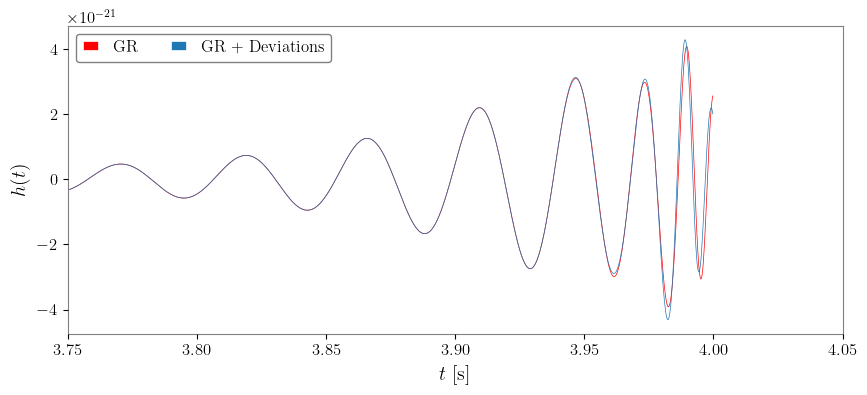

In [8]:
#setting up a standard IMRPhenomD waveform generator
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                          catch_waveform_errors=True, minimum_frequency = 20, maximum_frequency = 2048)

GR_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                                                   waveform_arguments=waveform_arguments,
                                                   frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
                                                   sampling_frequency=4096, 
                                                   duration=4
                                                   )

# generating the waveforms
corrected_waveform = corrected_waveform_generator.time_domain_strain(parameters=injection)
GR_waveform = GR_waveform_generator.time_domain_strain(parameters=injection)

# plotting
fig,ax = plt.subplots(figsize=(10,4))

ax.plot(GR_waveform_generator.time_array,np.real(GR_waveform['plus']-GR_waveform['cross']*1j),color='red',zorder=0,linewidth=0.5,alpha=1,label='GR')
ax.plot(corrected_waveform_generator.time_array,np.real(corrected_waveform['plus']-corrected_waveform['cross']*1j),color='tab:blue',zorder=1,linewidth=0.5,alpha=1,label='GR + Deviations')
ax.grid(False)
ax.set_xlim(3.75,4.05)
ax.legend(fancybox=True,framealpha=1,ncol=2)
ax.set_xlabel(r'$t$ [s]')
ax.set_ylabel(r'$h(t)$')
plt.show()

## Reconstructing the Waveform Corrections

To visualize the waveform corrections as $\Delta\mathcal{A}$ or $\Delta\phi$ as functions of frequency, we need to get the injected parameters in the form used by the frequency domain source model.

We start by getting a list of the frequency nodes in dimensionless frequency $\xi=GMf/c^3$. This is easily done using `GWCorrect.wfu.conversion.dimensionless_frequency_nodes_from_delta_xis`. This function takes in $\xi_0$, $\xi_n$, and a list of $\delta\xi_k$ parameters. In our case, we chose $n=3$, so there are $n-1=2$ $\delta\xi_k$ parameters.

In [9]:
delta_xis = [injection['delta_xi_1'],injection['delta_xi_2']]

dimensionless_frequency_nodes = wfu.conversion.dimensionless_frequency_nodes_from_delta_xis(injection['xi_0'],injection['xi_n'],delta_xis)
print(dimensionless_frequency_nodes)

[0.02161664 0.04144198 0.05153993 0.13655559]


We can convert these to SI frequency using `GWCorrect.wfu.conversion.convert_to_SI_frequency`. This function computes $f=c^3\xi/GM$, so we need the total system mass from the injected parameters. We can also convert back to dimensionless frequency using `GWCorrect.wfu.conversion.convert_to_dimensionless_frequency`.

In [10]:
total_mass = bilby.gw.conversion.generate_mass_parameters(injection)['total_mass']

frequency_nodes = wfu.conversion.convert_to_SI_frequency(dimensionless_frequency_nodes,total_mass)
print(frequency_nodes)

[ 27.4308369   52.58856848  65.40255664 173.28475657]


We also need the rescaled amplitude and phase correction parameters to be in lists. For the frequency rescaling, we also calculate the two component masses.

In [11]:
alpha_tildes = [injection[f'alpha_tilde_{k}'] for k in range(0,n+1)]
phi_tildes = [injection[f'phi_tilde_{k}'] for k in range(0,n+1)]

mass_1, mass_2 = bilby.gw.conversion.generate_mass_parameters(injection)['mass_1'], bilby.gw.conversion.generate_mass_parameters(injection)['mass_2']

The amplitude and phase corrections are then calculated using `GWCorrect.wfu.utils.amplitude_difference_from_parameters` and `GWCorrect.wfu.utils.phase_difference_from_parameters`. The first argument is the frequency array over which we want to generate the corrections. The last argument is the smoothing parameter $\gamma$, which controls the smooth interpolation functions and is usually 0.025. We can then plot the amplitude and phase corrections against frequency.

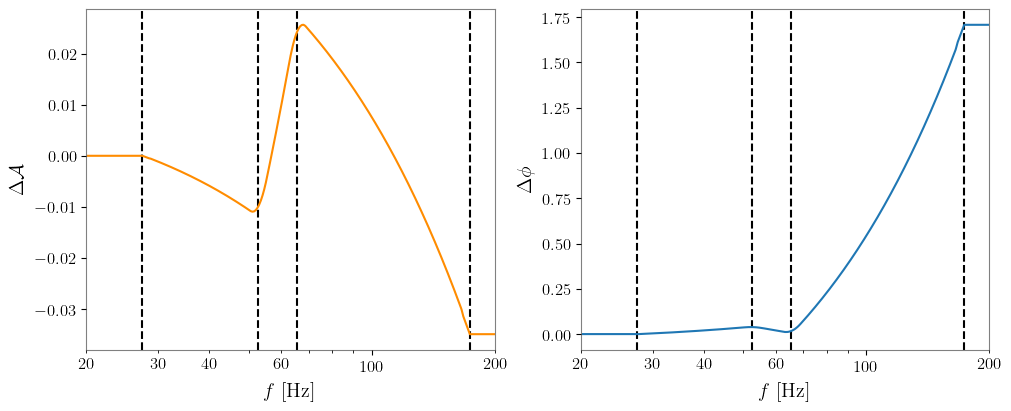

In [12]:
amplitude_correction = wfu.utils.amplitude_difference_from_parameters(corrected_waveform_generator.frequency_array,dimensionless_frequency_nodes,alpha_tildes,sigma_A_spline,mass_1,mass_2,0.025)
phase_correction = wfu.utils.phase_difference_from_parameters(corrected_waveform_generator.frequency_array,dimensionless_frequency_nodes,phi_tildes,sigma_phi_spline,mass_1,mass_2,0.025)

#plotting
fig,ax = plt.subplots(1,2,figsize=(10,4),layout='constrained')

ax[0].semilogx(corrected_waveform_generator.frequency_array,amplitude_correction,color='darkorange')
for i in range(n+1):
    ax[0].axvline(frequency_nodes[i],color='k',zorder=0,linestyle='dashed')
    
ax[0].set_xlim(20,200)
ax[0].set_ylabel(r'$\Delta\mathcal{A}$')
ax[0].set_xlabel(r'$f$ [Hz]')
ax[0].grid(False)

ax[1].semilogx(corrected_waveform_generator.frequency_array,phase_correction,color='tab:blue')
for i in range(n+1):
    ax[1].axvline(frequency_nodes[i],color='k',zorder=0,linestyle='dashed')
    
ax[1].set_xlim(20,200)
ax[1].set_ylabel(r'$\Delta\phi$')
ax[1].set_xlabel(r'$f$ [Hz]')
ax[1].grid(False)

plt.show()

## Creating the Prior

When using this waveform generator during parameter estimation, the most important step is setting up the prior distributions for each parameter. 

To start, we set some variables that will be used extensively to easily ensure consistency. We also make sure that we still have the $\sigma_\mathcal{A}$ and $\sigma_\phi$ splines. You can load this file at the top of this tutorial if you have not done so already.

In [13]:
n = 3
xi_min = 0.018
xi_max = 1/np.pi
duration = 4
minimum_frequency = 20
maximum_frequency = 2048
sampling_frequency = 4096

# load in the parameterization file above
sigma_A_spline, sigma_phi_spline = wfu.parameterization.sigma_splines_from_parameterization(parameterization)

Before creating the prior, we define the conversion function that allows the sampler to satisfy the constraints. `GWCorrect.wfu.conversion.conversion` takes in a dictionary of BBH source and correction parameters and returns the input parameters plus the frequency node constraint counter $\epsilon_f$, the amplitude constraint counter $\epsilon_\alpha$, and the total mass $M$. For these calculations, we must pass `n`, `xi_max`, `sigma_A_spline`, and `duration` into this function. See the documentation to see which are required for each calculation, as all are optional.

In [14]:
def conversion(parameters):
    return wfu.conversion.conversion(parameters,n=n,xi_max=xi_max,sigma_A_spline=sigma_A_spline,duration=duration)

Now we can create the prior of source parameters. This is the same as a standard prior, except that we must pass the conversion function into the `PriorDict` function to evaluate the constraints.

In [15]:
prior = bilby.core.prior.PriorDict(conversion_function = conversion) # conversion function goes here

prior['chirp_mass'] = bilby.gw.prior.UniformInComponentsChirpMass(name='chirp_mass',latex_label=r'$\mathcal{M}_c$',minimum=10,maximum=100,unit=r'$\mathrm{M}_{\odot}$')
prior['mass_ratio'] = bilby.gw.prior.UniformInComponentsMassRatio(name='mass_ratio',latex_label=r'$q$',minimum=0.125,maximum=1)
prior['chi_1'] = bilby.gw.prior.AlignedSpin(name='chi_1',latex_label=r'$\chi_1$')
prior['chi_2'] = bilby.gw.prior.AlignedSpin(name='chi_2',latex_label=r'$\chi_2$')
prior['geocent_time'] = bilby.gw.prior.Uniform(name='geocent_time',latex_label=r'$t_{c}$',minimum=1126259462.3,maximum=1126259462.5,unit='s')
prior['luminosity_distance'] = bilby.gw.prior.UniformSourceFrame(name='luminosity_distance',latex_label=r'$D_L$',minimum=10,maximum=10000,unit='Mpc')
prior['phase'] = bilby.core.prior.Uniform(name='phase',latex_label=r'$\phi_\mathrm{ref}$',minimum=0,maximum=2*np.pi,boundary='periodic')
prior['theta_jn'] = bilby.core.prior.Sine(name='theta_jn',latex_label=r'$\theta_{JN}$')
prior['ra'] = 1.77564066
prior['dec'] = -1.18781199
prior['psi'] = 1.49559484

We can then add the constraint priors. The total mass constraint is given by `GWCorrect.wfu.prior.TotalMassConstraint`, which restricts the total mass to $c^3\xi_\mathrm{max}/Gf_\mathrm{max}\leq M\leq c^3\xi_\mathrm{min}/Gf_\mathrm{min}$. $\epsilon_f$ and $\epsilon_\alpha$ are defined such that they can only be at positive integer values and their constraints are satisfied when they equal zero. We cannot set a constraint parameter equal to zero with bilby, so we constrain each parameter to a range of -0.5 to 0.5. The only possible value for each parameter in this range is zero, so we effectively bypass this limitation of bilby.

In [16]:
prior['total_mass'] = wfu.prior.TotalMassConstraint(name='total_mass',latex_label=r'$M$',minimum_frequency=minimum_frequency,maximum_frequency=maximum_frequency,unit=r'$\mathrm{M}_{\odot}$',xi_min=xi_min,xi_max=xi_max)
prior['epsilon_f'] = bilby.core.prior.Constraint(name='epsilon_f',latex_label=r'$\epsilon_f$',minimum=-0.5,maximum=0.5)
prior['epsilon_alpha'] = bilby.core.prior.Constraint(name='epsilon_alpha',latex_label=r'$\epsilon_\alpha$',minimum=-0.5,maximum=0.5)

For the rescaled waveform correction parameters, the prior distributions are always the same. $\tilde\alpha_0$ and $\tilde\varphi_0$ must always be equal to zero. The rest of $\tilde\alpha_k$ and $\tilde\varphi_k$ are assigned the prior $\mathcal{N}(0,1)$. Each $\delta\xi_k$ parameter is defined to be uniform between 0 and 1, so the priors are set accordingly.

In [17]:
prior['alpha_tilde_0'] = 0
prior['phi_tilde_0'] = 0

for k in range(1,n+1):
    prior[f'alpha_tilde_{k}'] = bilby.core.prior.Gaussian(name=f'alpha_tilde_{k}',latex_label=r'$\tilde\alpha_val$'.replace('val',str(k)),mu=0,sigma=1)
    prior[f'phi_tilde_{k}'] = bilby.core.prior.Gaussian(name=f'phi_tilde_{k}',latex_label=r'$\tilde\varphi_val$'.replace('val',str(k)),mu=0,sigma=1)

for k in range(1,n):
    prior[f'delta_xi_{k}'] = bilby.core.prior.Uniform(name=f'delta_xi_{k}',latex_label=r'$\delta\xi_val$'.replace('val',str(k)),minimum=0,maximum=1)

The outer frequency nodes, $\xi_0$ and $\xi_n$ respectively, have more complex priors that must be generated separately. The next section will go over this and add these priors to the prior dictionary.

### Outer Frequency Node Priors

The priors on the outer frequency nodes are motivated by where we expect a gravitational wave to intersect a detector's noise curve. To calculate this, we need amplitude spectral density data, a standard GR waveform generator, and a prior of source parameters to draw samples from.

In [18]:
asd_data = np.loadtxt('https://dcc.ligo.org/public/0165/T2000012/002/aligo_O4high.txt',comments='#') #sample O4 LIGO Hanford ASD data

# setting up an IMRPhenomD waveform generator
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                          catch_waveform_errors=True, minimum_frequency = 20, maximum_frequency = 2048)

GR_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                    waveform_arguments=waveform_arguments,
                    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
                    sampling_frequency=4096, 
                    duration=4
                )

# this is a shortcut to convert the full prior from the previous section into one that effectively only has the source parameters
# the GR waveform model ignores the waveform correction parameters and constraints, and copying the prior removes the conversion function
GR_prior = prior.copy()

20:55 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=4, sampling_frequency=4096, start_time=0, frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'reference_frequency': 20, 'catch_waveform_errors': True, 'minimum_frequency': 20, 'maximum_frequency': 2048})


By drawing thousands of source parameters, generating waveforms, and comparing the amplitudes of the waveforms with the amplitude spectral densities, we generate distributions for $\xi_0$ and $\xi_n$. These distributions can be approximated as Gaussian distributions, so we pull the means ($\mu_0$ and $\mu_n$) and standard deviations ($\sigma_0$ and $\sigma_n$). We generate these with `GWCorrect.wfu.outer_frequency_node_prior_parameters`. 

In [19]:
mu_0, sigma_0, mu_n, sigma_n = wfu.prior.outer_frequency_node_prior_parameters(GR_waveform_generator,asd_data,GR_prior,minimum_frequency,maximum_frequency)

Generating Distributions: 100%|██████████| 10000/10000 [00:26<00:00, 380.38it/s]


The outer frequency node priors are then Truncated Gaussian distributions with boundaries given by $\xi_\mathrm{min}$ and $\xi_\mathrm{max}$ and with their respective mean and standard deviation. These are then added to the full prior from the previous section. This completes the prior.

In [20]:
prior['xi_0'] = bilby.core.prior.TruncatedGaussian(name='xi_0',latex_label=r'$\xi_0$',mu=mu_0,sigma=sigma_0,minimum=xi_min,maximum=xi_max)
prior['xi_n'] = bilby.core.prior.TruncatedGaussian(name='xi_n',latex_label=r'$\xi_{n}$'.replace('n',str(n)),mu=mu_n,sigma=sigma_n,minimum=xi_min,maximum=xi_max)

prior

{'chirp_mass': bilby.gw.prior.UniformInComponentsChirpMass(minimum=10, maximum=100, name='chirp_mass', latex_label='$\\mathcal{M}_c$', unit='$\\mathrm{M}_{\\odot}$', boundary=None),
 'mass_ratio': bilby.gw.prior.UniformInComponentsMassRatio(minimum=0.125, maximum=1, name='mass_ratio', latex_label='$q$', unit=None, boundary=None, equal_mass=False),
 'chi_1': bilby.gw.prior.AlignedSpin(a_prior=Uniform(minimum=0, maximum=1, name=None, latex_label=None, unit=None, boundary=None), z_prior=Uniform(minimum=-1, maximum=1, name=None, latex_label=None, unit=None, boundary=None), name='chi_1', latex_label='$\\chi_1$', unit=None, boundary=None, minimum=-1.0, maximum=1.0, num_interp=100000),
 'chi_2': bilby.gw.prior.AlignedSpin(a_prior=Uniform(minimum=0, maximum=1, name=None, latex_label=None, unit=None, boundary=None), z_prior=Uniform(minimum=-1, maximum=1, name=None, latex_label=None, unit=None, boundary=None), name='chi_2', latex_label='$\\chi_2$', unit=None, boundary=None, minimum=-1.0, maximum

With this prior and corrected waveform generator, parameter estimation can be performed as usual. See [bilby's documentation](https://bilby-dev.github.io/bilby/visualising_the_results.html) for details.

## Analyzing a Result File

We load in a sample result file to examine the posterior distributions for these parameters.

In [21]:
# downloading the file and saving to tutorial files folder
try:
    os.mkdir('tutorial_files')
except:
    pass
file = requests.get('https://github.com/RyanSR71/GWCorrect/raw/refs/heads/main/files/wfu_sample_result_file.json', allow_redirects=True)
open("tutorial_files/wfu_sample_result_file.json", 'wb').write(file.content)

# loading the file
result = bilby.read_in_result("tutorial_files/wfu_sample_result_file.json")

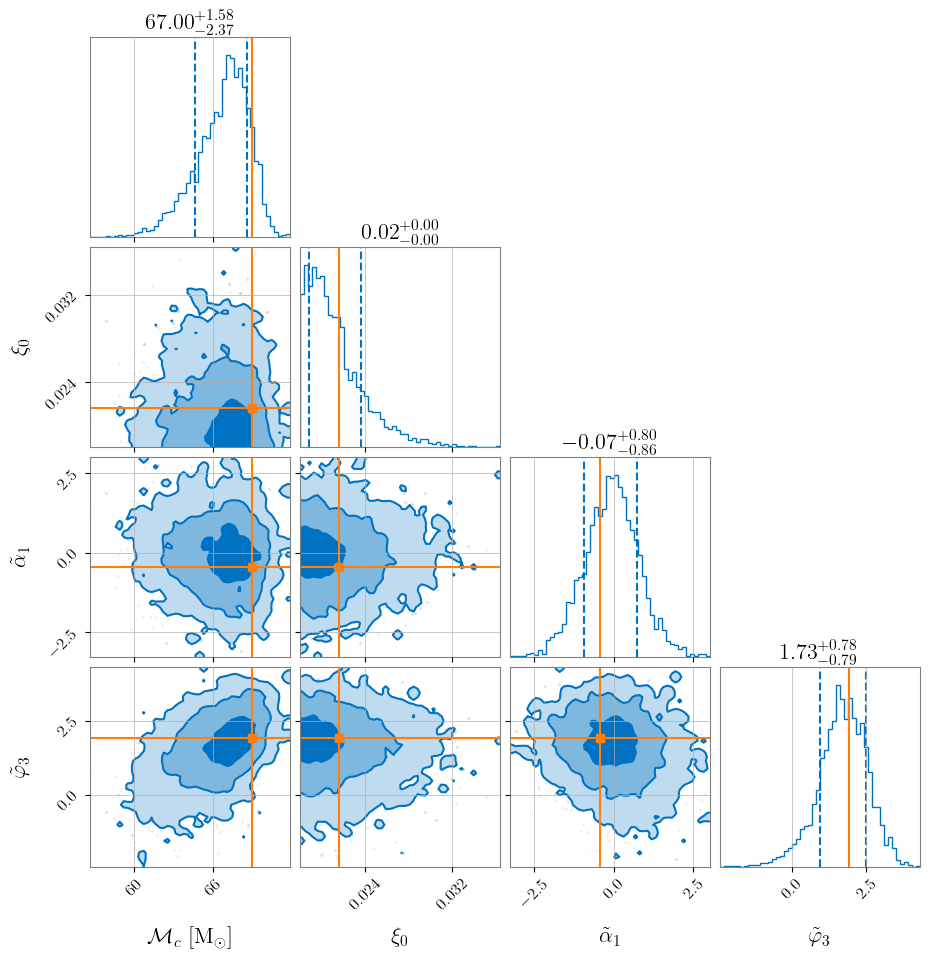

In [22]:
injection = dict(
    chirp_mass = 68.92936540942588,
    xi_0 = 0.02161663972711927,
    alpha_tilde_1 = -0.4446437774979714,
    phi_tilde_3 = 1.9273200044611765
)

result.plot_corner(save=False,truth=injection)
plt.show()